# Glioblastoma with oxygen

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sisyga/biolgca/blob/glioblastoma-oxygen/docs/source/examples/glioblastoma_oxygen.ipynb)

Glioblastoma cells switch between a migrating ("go") and a proliferating ("grow") phenotype. In the model of
Syga et al. (2024) each cell carries its own switch, inherited with mutations, and the switch responds to the
local cell density; evolution then selects how cells switch. Here the switch responds to **oxygen** instead,
which blood vessels supply and the cells consume (Whiteside et al., in preparation).

This notebook builds the model from scratch, one mechanism at a time, with BioLGCA's building blocks: the
`pde` operator for oxygen, new rules written with `@reaction` and `@interaction`, and built-in rules for the
switch, division, death and migration.

1. physical parameters in lattice units;
2. the lattice, the vessels and the initial tumour;
3. oxygen: diffusion, uptake by cells, and vessels as sources;
4. vessels that tumour cells clog, and stable ones that they do not;
5. the oxygen-dependent go-or-grow switch with evolving κ and θ;
6. division and death in normoxia, hypoxia and anoxia;
7. surgery;
8. the whole model in 1D and 2D.

The same model is packaged as `lgca.examples.glioblastoma_oxygen`.

In [1]:
# In Google Colab this cell installs BioLGCA (about a minute); elsewhere it does nothing.
import importlib.util
import subprocess
import sys

if "google.colab" in sys.modules and importlib.util.find_spec("lgca") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "biolgca @ git+https://github.com/sisyga/biolgca@glioblastoma-oxygen"], check=True)

In [2]:
import matplotlib.pyplot as plt
import numpy as np

from lgca.fields import PDESpec, reaction
from lgca.lattice_state import LatticeState
from lgca.model import (
    AnalysisSpec, Description, ModelSpec, SpaceSpec, StateSpec, TimeSpec, build_model, run_model,
)
from lgca.pipeline import InteractionPipelineSpec
from lgca.plot_data import mean_trait
from lgca.rules import interaction
from lgca.simulation import FieldRecorder, PopulationRecorder, Schedule

## 1. Parameters in lattice units

A node is a voxel of tissue $\Delta x$ = 50 µm wide that holds up to $K = 100$ cells, so 1000 nodes span 5 cm.
Oxygen is measured relative to the oxygen of the blood, $O_v$ = 60 mmHg, so it lies between 0 and 1, and the
switch reads it directly.

Oxygen obeys (Martínez-González et al. 2012)

$$\partial_t O = D\,\Delta O - \alpha\, n\, \frac{O}{K_m + O},$$

with $n$ the cells at a node, $\alpha$ the maximal uptake of a cell and $K_m$ the Michaelis constant. Oxygen
crosses a node in about a second, cells divide in about a day: at every step the field is at equilibrium with
the cells, and only the ratio of diffusion to uptake matters. We therefore express both per second.

| Quantity | Value | Note |
|---|---|---|
| node width $\Delta x$ | 50 µm | 1000 nodes = 5 cm |
| capacity $K$ | 100 cells | Syga et al. 2024 |
| vessel spacing | 200 µm | one vessel per (200 µm)³ of brain |
| $D$ | 2·10⁻⁵ cm²/s | to check |
| uptake $\alpha$ | 10⁻¹¹ µmol/(cell s) | after Martínez-González et al. 2012 |
| $K_m$ | 2.5 mmHg | Martínez-González et al. 2012 |
| $O_v$ | 60 mmHg | Whiteside's "high oxygen" runs (24 mmHg: "low oxygen") |
| hypoxia | 7 mmHg | her cutoff 0.117 |
| anoxia | 0.7 mmHg | to check |

In [3]:
node_size = 50.0  # µm
capacity = 100  # cells per node
vessel_spacing = 200.0  # µm
diffusion = 2000.0  # µm²/s
uptake = 1e-11  # µmol/(cell s)
michaelis = 2.5  # mmHg
vessel_oxygen = 60.0  # mmHg
mmHg = 1.316e-3  # µmol/cm³ per mmHg
hypoxia, anoxia = 7.0 / vessel_oxygen, 0.7 / vessel_oxygen  # relative to the blood

node_volume = (node_size * 1e-4) ** 3  # cm³
D = diffusion / node_size**2  # nodes² per s
alpha = uptake / (node_volume * vessel_oxygen * mmHg)  # per cell and s, relative to the blood
K_m = michaelis / vessel_oxygen
print(f"D = {D:.3g} nodes²/s, α = {alpha:.3g} per cell and s, K_m = {K_m:.3g}")

# the distance over which a full node uses up the blood's oxygen
penetration = np.sqrt(D / (capacity * alpha))
print(f"penetration length in full tissue: {penetration:.1f} nodes = {node_size * penetration:.0f} µm")

D = 0.8 nodes²/s, α = 0.00101 per cell and s, K_m = 0.0417
penetration length in full tissue: 2.8 nodes = 140 µm


The penetration length is about three nodes (140 µm), shorter than the 200 µm between vessels: tissue at
full density between vessels runs out of oxygen, and that is what makes the vessels matter.

## 2. Lattice, vessels and the initial tumour

The model is identity-based (every cell has its own traits) and without volume exclusion: a node holds any
number of cells in each channel, and the capacity enters only as a crowding scale. A 1D node has two velocity
channels and one rest channel, a hexagonal node six and one; the rest channel is the last.

**Vessels** are a field, `vessels`: 1 at a node with a vessel that can clog, 2 at a stable vessel that never
clogs, 0 elsewhere. A node holds a vessel with probability $(\Delta x / 200\,\mu\text{m})^d$ in $d$
dimensions; a few of them, chosen at random, are stable.

**The tumour** starts as $K$ resting cells at the first node (1D, where the line is a radius) or at the centre
(2D). Every cell gets its genotype, the oxygen sensitivity $\kappa$ and the critical oxygen $\theta$, drawn
uniformly from $[-4, 4]$ and $[0, 1]$. The traits `r_b` and `r_d` will hold each cell's division and death
probabilities (section 6).

In [4]:
def make_vessels(dims, rng, stable=0):
    """1 at a vessel that can clog, 2 at one of `stable` vessels that never clog, 0 elsewhere."""
    p = min(1.0, (node_size / vessel_spacing) ** len(dims))
    vessels = (rng.random(dims) < p).astype(float)
    if stable:
        vessels.flat[rng.choice(np.flatnonzero(vessels), stable, replace=False)] = 2.0
    return vessels


def initial_tumour(dims, rng, cells=capacity):
    """`cells` resting cells at the first node (1D) or the centre (2D), and their traits."""
    channels = 3 if len(dims) == 1 else 7
    origin = (0,) if len(dims) == 1 else tuple(n // 2 for n in dims)
    nodes = np.zeros(tuple(dims) + (channels,), dtype=np.int64)
    nodes[origin + (channels - 1,)] = cells  # the rest channel
    traits = {"kappa": rng.uniform(-4, 4, cells), "theta": rng.uniform(0, 1, cells), "r_b": 0.0, "r_d": 0.0}
    return nodes, traits


rng = np.random.default_rng(3)
vessels_1d = make_vessels((200,), rng, stable=3)
print(f"{(vessels_1d > 0).sum()} vessels on 200 nodes, {(vessels_1d == 2).sum()} of them stable")

44 vessels on 200 nodes, 3 of them stable


## 3. Oxygen from vessels

The built-in `pde` operator (`PDESpec`) solves the oxygen equation. Uptake by cells is one of its cell terms,
`{"uptake": α, "saturation": K_m}`, which gives every cell the uptake $\alpha O / (K_m + O)$.

A vessel is a Dirichlet point source: it holds the oxygen at the blood's value. We write it as a **reaction**,
a function of the lattice state and the field that returns a production and a loss rate: at an open vessel
oxygen relaxes to 1 at a very high rate, which pins it there. In this form the solver keeps $O \ge 0$.

In [5]:
@reaction(name="gbm.vessels")
def vessel_supply(state, c, rate=1e6, field="vessels"):
    """Oxygen relaxes to the blood's, 1, at `rate` where `field` marks an open vessel."""
    open_vessels = rate * (state.field(field) > 0)
    return open_vessels, open_vessels  # production, loss rate


def oxygen_operator():
    return PDESpec(field="oxygen", diffusion=D, solver="steady", reactions=[{"name": "gbm.vessels"}],
                   cells=[{"uptake": alpha, "saturation": K_m}])

To see the field, we build a model with this operator only, on a line of 200 nodes with 1 mm of tumour at
full density on the left. The steady solver solves the field when the model is built.

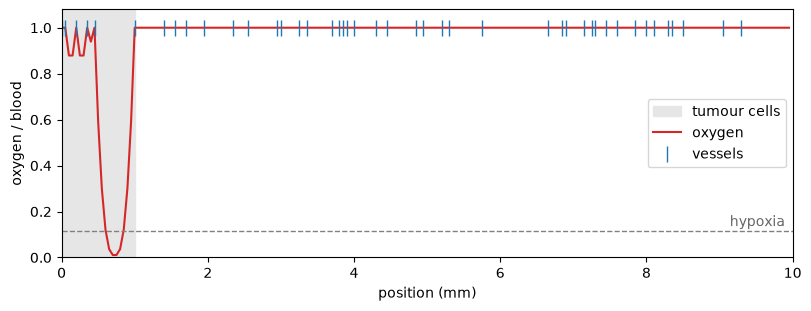

In [6]:
nodes = np.zeros((200, 3), dtype=np.int64)
nodes[:20, 2] = capacity
oxygen_only = ModelSpec(
    space=SpaceSpec(geometry="lin", dims=200, boundary="reflecting"),
    state=StateSpec(nodes=nodes, restchannels=1, volume_exclusion=False, capacity=capacity,
                    fields={"oxygen": 1.0, "vessels": vessels_1d}),
    time=TimeSpec(steps=0, seed=1),
    dynamics=InteractionPipelineSpec(operators=[oxygen_operator()]),
)
oxygen = LatticeState(build_model(oxygen_only).lgca).field("oxygen")

x = np.arange(200) * node_size / 1000  # mm
fig, axis = plt.subplots(figsize=(8, 3), constrained_layout=True)
axis.axvspan(0, 1, color="0.9", label="tumour cells")
axis.plot(x, oxygen, color="tab:red", label="oxygen")
axis.plot(x[vessels_1d > 0], np.ones((vessels_1d > 0).sum()), "|", color="tab:blue", markersize=12,
          label="vessels")
axis.axhline(hypoxia, ls="--", color="0.5", lw=1)
axis.text(9.9, hypoxia + 0.02, "hypoxia", ha="right", color="0.4")
axis.set(xlabel="position (mm)", ylabel="oxygen / blood", xlim=(0, 10), ylim=(0, 1.08))
axis.legend(loc="center right")
plt.show()

Healthy tissue (no tumour cells) keeps the blood's oxygen everywhere: only tumour cells consume in this
model. Inside the tumour, oxygen peaks at every vessel and falls into hypoxia between them.

## 4. Clogging and stable vessels

Tumour cells clog vessels. A new rule of kind `field` (it changes fields only) closes an open vessel with
probability `rate * n / K` per step, for `n` cells at its node. Closed vessels stay closed (no angiogenesis);
stable vessels (2) never close. Random numbers come from `state.rng`, so runs repeat from their seed, and the
field is changed only through `state.set_field`, so a failed step is rolled back.

In [7]:
@interaction(kind="field", families=("ib", "nove_ib"), name="gbm.clogging")
def clogging(state, rate=0.0, field="vessels"):
    """An open vessel closes with probability `rate * n / capacity` per step; stable vessels (2) never do."""
    if rate <= 0:
        return
    vessels = state.field(field)
    p = np.clip(rate * state.density / state.capacity, 0.0, 1.0)
    closing = (vessels == 1) & (state.rng.random(state.dims) < p)
    if closing.any():
        state.set_field(field, np.where(closing, 0.0, vessels))

## 5. The go-or-grow switch reads oxygen

A cell rests (and may divide) with probability

$$r(O) = \tfrac{1}{2}\left(1 + \tanh\left(\kappa\,(O - \theta)\right)\right)$$

and migrates otherwise, where $O$ is the oxygen at its node. The built-in rule `go_or_rest` takes this as a
switching probability (`lgca.switching`) with a `field` cue; `kappa` and `theta` name cell traits, so each cell
switches with its own genotype. A random walk of the migrating cells follows it.

With $\kappa > 0$ cells proliferate where oxygen is high and migrate where it is low (the attractive
strategy); with $\kappa < 0$ the reverse (repulsive); with $\kappa \approx 0$ they switch regardless of oxygen
(independent). With density as the cue, Syga et al. (2024) called $\kappa < 0$ repulsive for the same reason,
moving away from crowding.

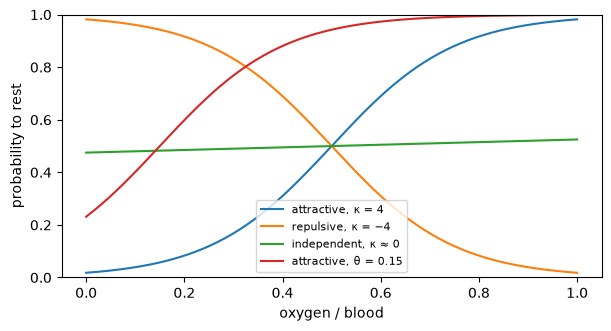

In [8]:
switch = {"name": "go_or_rest", "parameters": {"probability": {"max": 1.0, "cues": [
    {"name": "field", "field": "oxygen", "kappa": "kappa", "theta": "theta"}]}}}
migration = {"name": "random_walk", "parameters": {"channels": "velocity"}}

o = np.linspace(0, 1, 200)
fig, axis = plt.subplots(figsize=(6, 3.2), constrained_layout=True)
for kappa, theta, label in [(4, 0.5, "attractive, κ = 4"), (-4, 0.5, "repulsive, κ = −4"),
                            (0.1, 0.5, "independent, κ ≈ 0"), (4, 0.15, "attractive, θ = 0.15")]:
    axis.plot(o, (1 + np.tanh(kappa * (o - theta))) / 2, label=label)
axis.set(xlabel="oxygen / blood", ylabel="probability to rest", ylim=(0, 1))
axis.legend(fontsize=8)
plt.show()

## 6. Division and death in three oxygen zones

Division and death are step functions of oxygen: one value each in normoxia ($O \ge$ 7 mmHg), hypoxia
(0.7 to 7 mmHg) and anoxia (below 0.7 mmHg). A new rule writes the values of the zone of its node into the
traits `r_b` and `r_d` of every cell. It changes traits but not cells, so it is a `phenotype_switch`. The
built-in `birth_death` then reads the probabilities by trait name: every cell dies with `r_d`, and resting
cells divide with `r_b * (1 - n / K)`. Daughters rest, and inherit κ and θ with small normal changes (standard
deviations 0.2 and 0.05; θ stays in [0, 1]), given as the `mutation` of the division, so the population
evolves.

The probabilities per zone are assumptions to be checked: division 1, 0.5, 0; death 0.1, 0.2, 0.5.

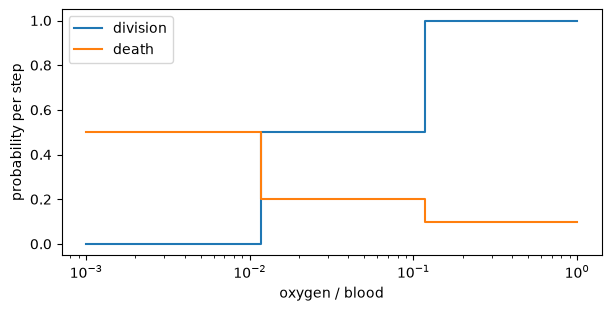

In [9]:
@interaction(kind="phenotype_switch", families=("ib", "nove_ib"), name="gbm.oxygen_zones")
def oxygen_zones(state, hypoxia=0.1, anoxia=0.01, division=(1.0, 0.5, 0.0), death=(0.1, 0.2, 0.5)):
    """Set the traits r_b and r_d of every cell to the values of its node's zone: normoxia, hypoxia, anoxia."""
    cells = state.cells
    if not len(cells):
        return
    oxygen = state.field("oxygen")
    zone = np.where(oxygen >= hypoxia, 0, np.where(oxygen >= anoxia, 1, 2))[cells.node]
    every = np.ones(len(cells), dtype=bool)
    cells.set_trait(every, "r_b", np.asarray(division, dtype=float)[zone])
    cells.set_trait(every, "r_d", np.asarray(death, dtype=float)[zone])


zones = {"name": "gbm.oxygen_zones", "parameters": {
    "hypoxia": hypoxia, "anoxia": anoxia, "division": [1.0, 0.5, 0.0], "death": [0.1, 0.2, 0.5]}}
death = {"name": "birth_death", "parameters": {"death_rate": "r_d"}}
mutation = {"traits": {
    "kappa": {"distribution": "normal", "scale": 0.2},
    "theta": {"distribution": "normal", "scale": 0.05, "bounds": [0.0, 1.0], "at_bounds": "redraw"},
}}
division = {"name": "birth_death", "parameters": {"birth_rate": "r_b", "channels": "rest", "mutation": mutation}}

fig, axis = plt.subplots(figsize=(6, 3), constrained_layout=True)
o = np.logspace(-3, 0, 400)
zone = np.where(o >= hypoxia, 0, np.where(o >= anoxia, 1, 2))
axis.step(o, np.array([1.0, 0.5, 0.0])[zone], where="post", label="division")
axis.step(o, np.array([0.1, 0.2, 0.5])[zone], where="post", label="death")
axis.set(xscale="log", xlabel="oxygen / blood", ylabel="probability per step")
axis.legend()
plt.show()

## 7. Surgery

A resection removes the dense tumour at one step: at every node with at least 10 % of the capacity, a cell is
removed with probability 99.9 %, and the vessels there go too. It removes cells, so it is a `birth_death`
rule; `state.step` is the number of the step being taken.

In [10]:
@interaction(kind="birth_death", families=("ib", "nove_ib"), name="gbm.resection")
def resection(state, at_step=-1, fraction=0.999, threshold=0.1):
    """In step `at_step`, remove a `fraction` of the cells and all vessels where the tumour is dense."""
    if state.step != at_step:
        return
    tumour = state.density >= threshold * state.capacity
    p = np.where(tumour, fraction, 0.0)
    state.remove_cells(p[..., None, None] * np.ones((1, state.velocitychannels + state.restchannels)))
    state.set_field("vessels", np.where(tumour, 0.0, state.field("vessels")))

## 8. The whole model

One time step runs the operators in their order, then propagation: oxygen (steady), clogging, the zones,
death, the switch, division with mutation, and the random walk. `build_spec` puts the pieces of the previous
sections together for a line or a hexagonal lattice.

In [11]:
def build_spec(geometry="lin", size=400, steps=800, clogging=0.0, stable=0, resect_at=None, seed=1,
               record_every=10):
    rng = np.random.default_rng(seed)
    dims = (size,) if geometry == "lin" else (size, size)
    nodes, traits = initial_tumour(dims, rng)
    vessels = make_vessels(dims, rng, stable=stable)
    operators = [oxygen_operator(), {"name": "gbm.clogging", "parameters": {"rate": clogging}}]
    if resect_at is not None:
        operators.append({"name": "gbm.resection", "parameters": {"at_step": resect_at}})
    operators += [zones, death, switch, division, migration]
    return ModelSpec(
        description=Description(title=f"Glioblastoma with oxygen, clogging {clogging}"),
        space=SpaceSpec(geometry=geometry, dims=size if geometry == "lin" else dims, boundary="reflecting"),
        state=StateSpec(nodes=nodes, restchannels=1, identity_based=True, volume_exclusion=False,
                        capacity=capacity, traits=traits, fields={"oxygen": 1.0, "vessels": vessels}),
        time=TimeSpec(steps=steps, seed=seed),
        dynamics=InteractionPipelineSpec(operators=operators),
        analysis=AnalysisSpec(observers=[
            PopulationRecorder(), FieldRecorder(["oxygen", "vessels"], schedule=Schedule(every=record_every))]),
    )


for operator in build_spec().dynamics.operators:
    print(operator["name"] if isinstance(operator, dict) else operator.name)

pde
gbm.clogging
gbm.oxygen_zones
birth_death
go_or_rest
birth_death
random_walk


### 1D: fixed vessels and clogging

We step the model ourselves and record, every few steps, the cells, the oxygen and the mean κ and θ per node.
Without clogging the tumour fills the tissue and oxygen stays patterned by the vessels; with clogging a wave
invades ahead of an anoxic core.

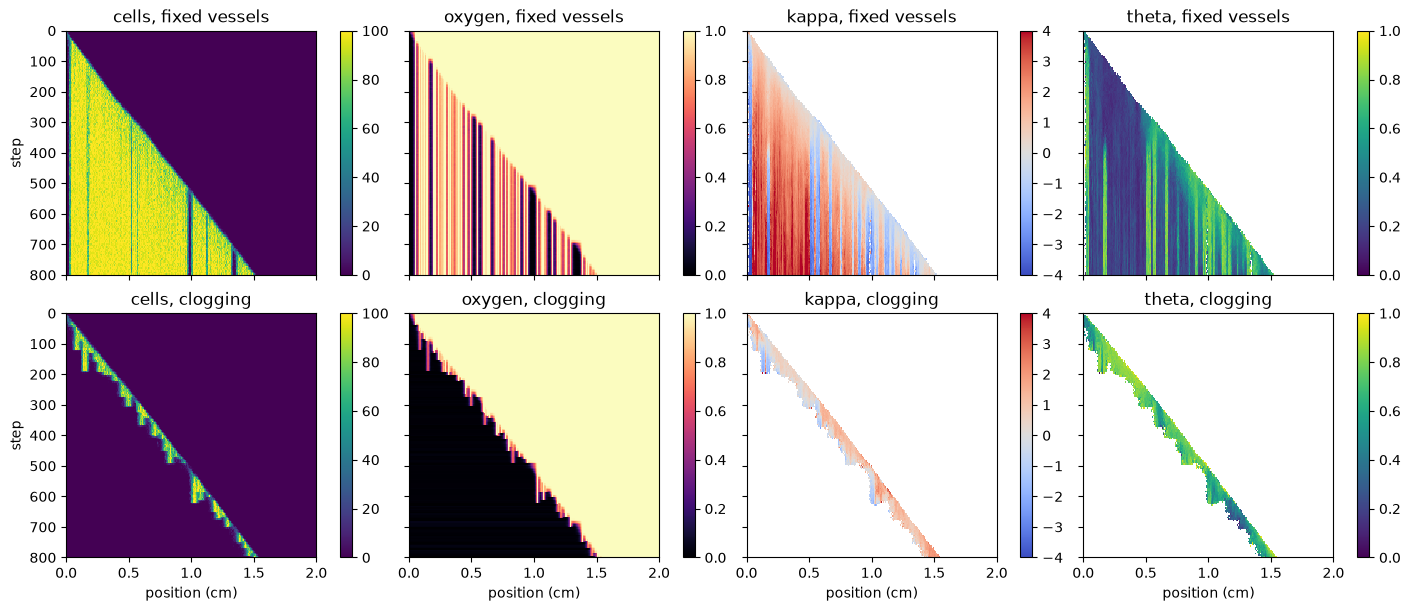

In [12]:
def kymographs(spec, every=5):
    model = build_model(spec)
    lgca = model.lgca
    record = {"steps": [], "cells": [], "oxygen": [], "kappa": [], "theta": []}
    for step in range(spec.time.steps + 1):
        if step % every == 0:
            record["steps"].append(step)
            record["cells"].append(lgca.cell_density[lgca.nonborder].copy())
            record["oxygen"].append(LatticeState(lgca).field("oxygen").copy())
            record["kappa"].append(mean_trait(lgca, "kappa"))
            record["theta"].append(mean_trait(lgca, "theta"))
        if step < spec.time.steps:
            model.step()
    return {key: np.array(values) for key, values in record.items()}


runs = {clogging: kymographs(build_spec("lin", size=400, steps=800, clogging=clogging)) for clogging in (0.0, 0.05)}

fig, axes = plt.subplots(2, 4, figsize=(14, 6), constrained_layout=True, sharex=True, sharey=True)
for row, (clogging, record) in enumerate(runs.items()):
    extent = (0, 400 * node_size * 1e-4, record["steps"][-1], 0)
    for axis, key, cmap, vmin, vmax in zip(axes[row], ("cells", "oxygen", "kappa", "theta"),
                                           ("viridis", "magma", "coolwarm", "viridis"),
                                           (0, 0, -4, 0), (100, 1, 4, 1)):
        image = axis.imshow(record[key], aspect="auto", extent=extent, cmap=cmap, vmin=vmin, vmax=vmax,
                            interpolation="nearest")
        axis.set_title(f"{key}, {'clogging' if clogging else 'fixed vessels'}")
        fig.colorbar(image, ax=axis)
for axis in axes[1]:
    axis.set_xlabel("position (cm)")
for axis in axes[:, 0]:
    axis.set_ylabel("step")
plt.show()

### 2D: clogging with stable vessels

On the hexagonal lattice the tumour grows from the centre. With clogging it becomes a ring that invades ahead
of an anoxic core; around the stable vessels (green circles) cells survive inside the core, a perivascular
niche.

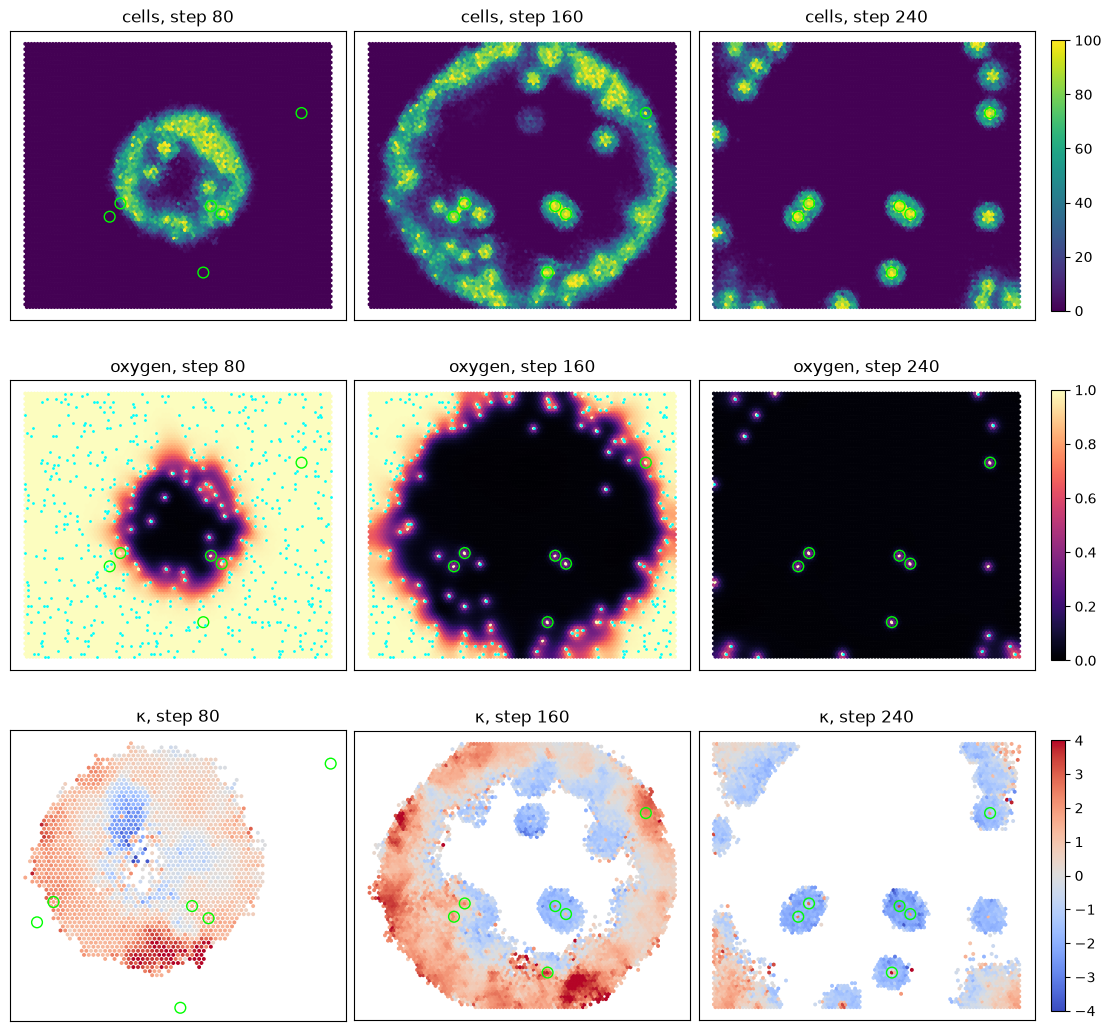

In [13]:
model = build_model(build_spec("hex", size=100, steps=240, clogging=0.05, stable=6, seed=1))
lgca = model.lgca
x, y = lgca.xcoords, lgca.ycoords
fig, axes = plt.subplots(3, 3, figsize=(11, 10.5), constrained_layout=True)
done = 0
for column, steps in enumerate((80, 160, 240)):
    for _ in range(steps - done):
        model.step()
    done = steps
    state = LatticeState(lgca)
    oxygen, vessels = state.field("oxygen"), state.field("vessels")
    panels = [(lgca.cell_density[lgca.nonborder], "viridis", 0, 100, "cells"),
              (oxygen, "magma", 0, 1, "oxygen"), (mean_trait(lgca, "kappa"), "coolwarm", -4, 4, "κ")]
    for row, (values, cmap, vmin, vmax, name) in enumerate(panels):
        axis = axes[row, column]
        image = axis.scatter(x.ravel(), y.ravel(), c=values.ravel(), s=4, marker="h", cmap=cmap,
                             vmin=vmin, vmax=vmax)
        axis.scatter(x[vessels == 2], y[vessels == 2], s=60, facecolors="none", edgecolors="lime")
        if name == "oxygen":
            axis.scatter(x[vessels == 1], y[vessels == 1], s=1, c="cyan")
        axis.set(aspect="equal", xticks=[], yticks=[], title=f"{name}, step {steps}")
        if column == 2:
            fig.colorbar(image, ax=axis, shrink=0.8)
plt.show()

### Resection

With `resect_at`, the resection runs in that step. The cells that remain, mostly at the invasive front where
oxygen is, regrow the tumour.

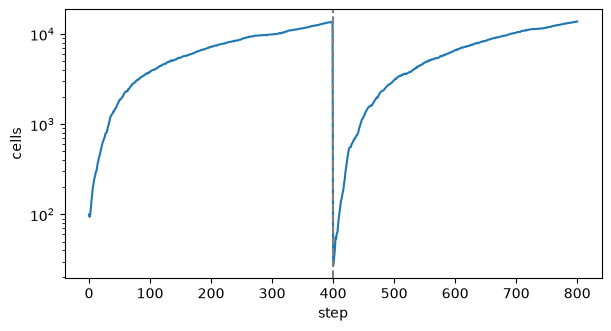

In [14]:
result = run_model(build_spec("lin", size=400, steps=800, resect_at=400, seed=2), showprogress=False)
steps = result.data.steps("population")
fig, axis = plt.subplots(figsize=(6, 3.2), constrained_layout=True)
axis.semilogy(steps, np.maximum(result.data["population"], 1))
axis.axvline(400, color="0.5", ls="--")
axis.set(xlabel="step", ylabel="cells")
plt.show()

## References

Syga S, Jain HP, Krellner M, Hatzikirou H, Deutsch A (2024) Evolution of phenotypic plasticity leads to tumor
heterogeneity with implications for therapy. PLoS Comput Biol 20(8): e1012003.

Martínez-González A, Calvo GF, Pérez Romasanta LA, Pérez-García VM (2012) Hypoxic cell waves around necrotic
cores in glioblastoma: a biomathematical model and its therapeutic implications. Bull Math Biol 74:2875–2896.